In [1]:
import pandas as pd
df_small = pd.read_csv('IRIS.csv')
df_small

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [2]:
from sklearn.preprocessing import StandardScaler

# Separate features from the target
X = df_small.drop('species', axis=1)
y = df_small['species']

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [3]:
import numpy as np

# Calculate Covariance Matrix
cov_matrix = np.cov(X_scaled.T)
print("Covariance Matrix:\n", cov_matrix)

Covariance Matrix:
 [[ 1.00671141 -0.11010327  0.87760486  0.82344326]
 [-0.11010327  1.00671141 -0.42333835 -0.358937  ]
 [ 0.87760486 -0.42333835  1.00671141  0.96921855]
 [ 0.82344326 -0.358937    0.96921855  1.00671141]]


In [4]:
from sklearn.decomposition import PCA

# Initialize PCA to keep 2 components
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['species'] = y.values

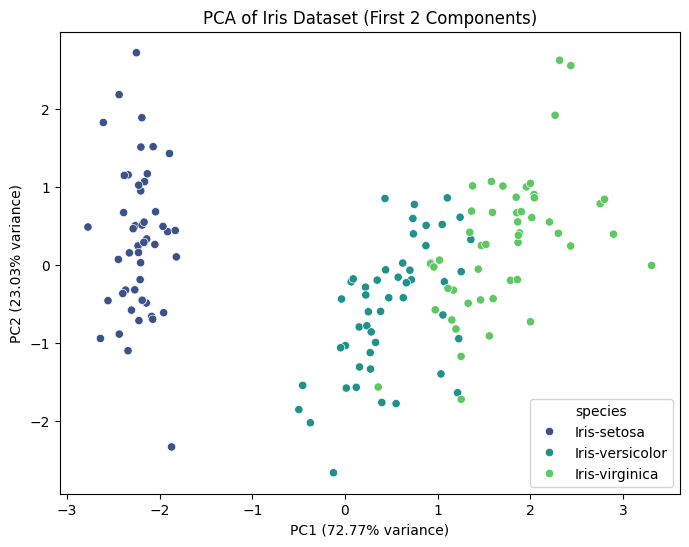

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='species', palette='viridis')
plt.title('PCA of Iris Dataset (First 2 Components)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)')
plt.show()

In [6]:
# This shows the "recipe" for each Principal Component
components_df = pd.DataFrame(
    pca.components_, 
    columns=X.columns, 
    index=['PC1', 'PC2']
)
print(components_df)

     sepal_length  sepal_width  petal_length  petal_width
PC1      0.522372    -0.263355      0.581254     0.565611
PC2      0.372318     0.925556      0.021095     0.065416


In [7]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
df_cancer = pd.DataFrame(data.data, columns=data.feature_names)
y_cancer = data.target

# 1. Scale the data
X_cancer_scaled = StandardScaler().fit_transform(df_cancer)

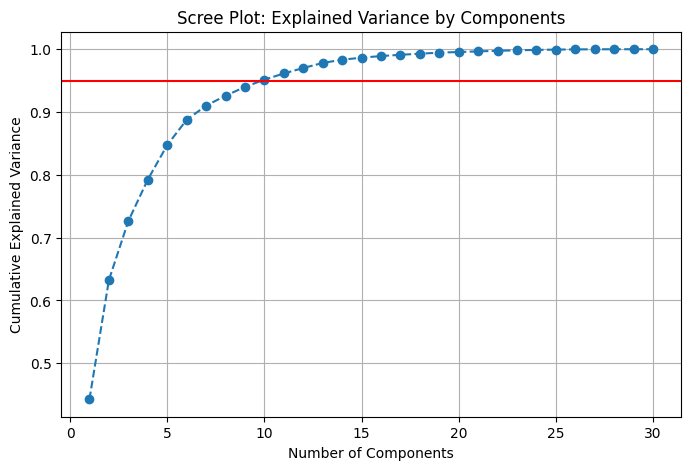

In [8]:
pca_30 = PCA(n_components=30)
pca_30.fit(X_cancer_scaled)

# Calculate cumulative variance
cumulative_variance = np.cumsum(pca_30.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 31), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.95, color='r', linestyle='-') # 95% threshold
plt.title('Scree Plot: Explained Variance by Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid()
plt.show()

In [15]:
pca = PCA(n_components=10)
X_pca = pca.fit_transform(X_cancer_scaled)

In [16]:
total_variance = np.sum(pca.explained_variance_ratio_)
print(f"By using 10 components, we kept {total_variance:.2%} of the original information.")

By using 10 components, we kept 95.16% of the original information.


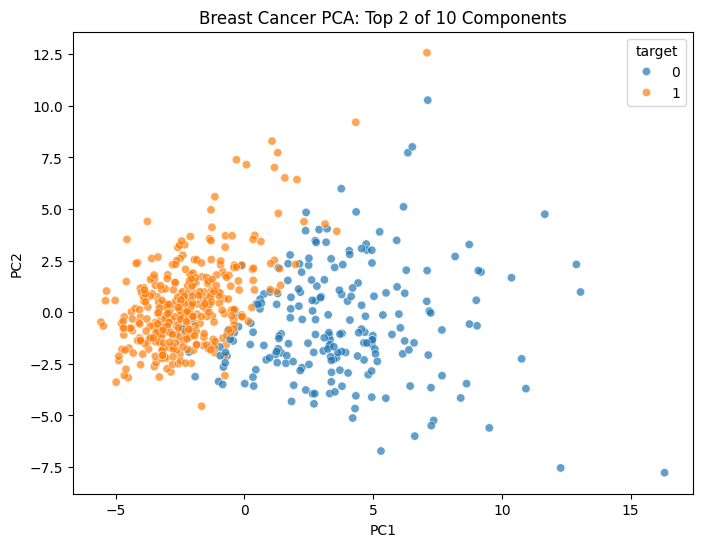

In [17]:
# Create the 10-component DataFrame
column_names = [f'PC{i+1}' for i in range(10)]
pca_df_cancer = pd.DataFrame(data=X_pca, columns=column_names)
pca_df_cancer['target'] = y_cancer

# Plot the first two
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df_cancer, x='PC1', y='PC2', hue='target', alpha=0.7)
plt.title('Breast Cancer PCA: Top 2 of 10 Components')
plt.show()

In [8]:
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

faces = fetch_olivetti_faces()
X_faces = faces.data
y_faces = faces.target

Number of components to explain 90% variance: 66


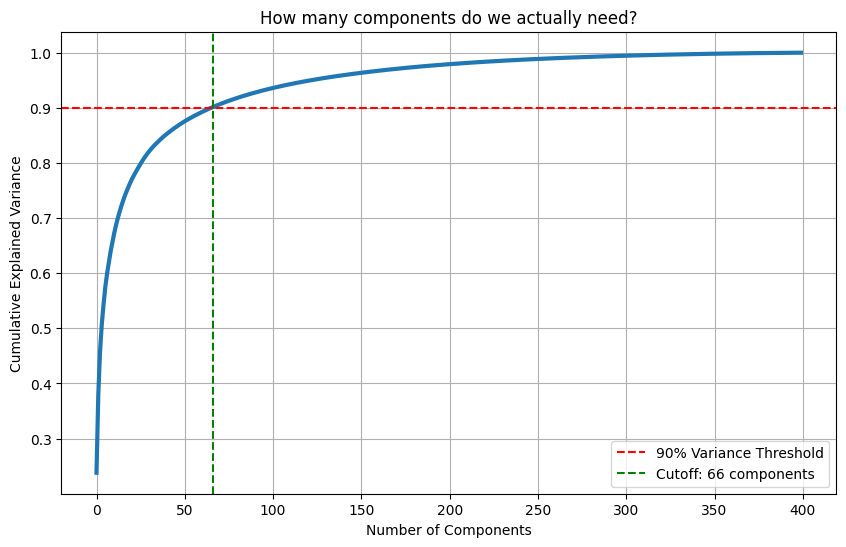

In [15]:
# 1. Fit PCA with a large number of components to see the full picture
# (Max components possible is the number of images: 400)
pca_full = PCA(n_components=400)
pca_full.fit(X_faces)

# 2. Calculate the cumulative sum of variance
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# 3. Find the exact math: How many components for 90%/95% variance?
n_90 = np.where(cumulative_variance >= 0.90)[0][0] + 1
#n_90 = np.where(cumulative_variance >= 0.95)[0][0] + 1
print(f"Number of components to explain 90% variance: {n_90}")

# 4. Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(cumulative_variance, linewidth=3)
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('How many components do we actually need?')

# Add a marker for the 90% threshold
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Variance Threshold')
plt.axvline(x=n_90, color='g', linestyle='--', label=f'Cutoff: {n_90} components')
plt.legend()
plt.grid(True)
plt.show()

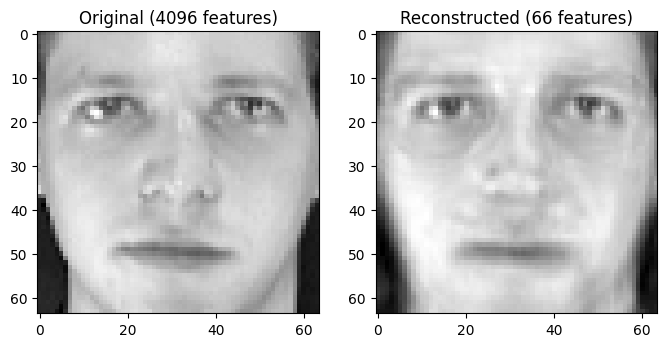

In [14]:
# keeping 66 components for 90 variance
pca_66 = PCA(n_components=66)
X_pca_66 = pca_66.fit_transform(X_faces)
X_reconstructed_66 = pca_66.inverse_transform(X_pca_66)

# keeping 123 components for 95% variance
#pca_66 = PCA(n_components=123)
#X_pca_66 = pca_66.fit_transform(X_faces)
#X_reconstructed_66 = pca_66.inverse_transform(X_pca_66)

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(X_faces[0].reshape(64, 64), cmap='gray')
plt.title("Original (4096 features)")

plt.subplot(1, 2, 2)
plt.imshow(X_reconstructed_66[0].reshape(64, 64), cmap='gray')
plt.title("Reconstructed (66 features)")
plt.show()